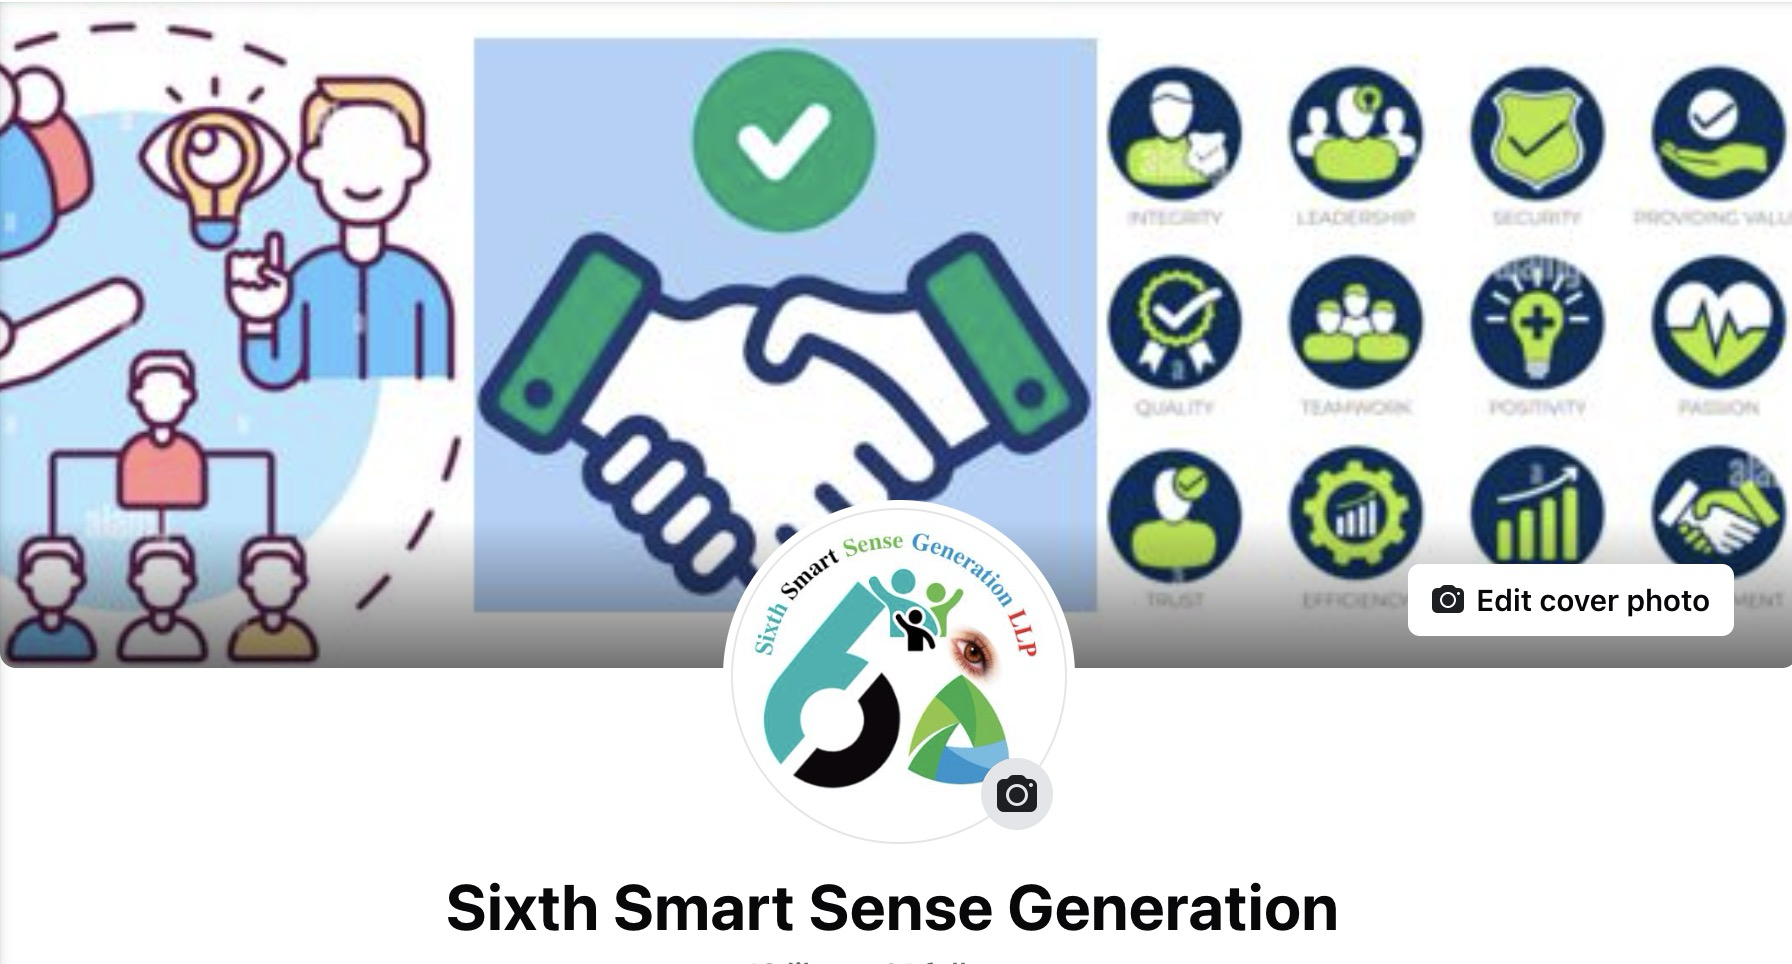

Mobility-Guided-Intelligent-Assistant - Skeleton File

Authors			    :	Kyaw Kyaw Oo, xxxx , Zhengyang Cui<br>
Emails              :   kyaw.consulting@gmail.com, xxxxx@gmail.com,s cuiz38@mcmaster.ca
Group No			:   Sixth Smart Sense Generation<br>
Started Date        :   Jan 28, 2025<br>
Version             :   1<br>
Released Date    	: 	<br>>
Version             :   2 <br>

CopyRight@2024 by Sixth Smart Sense Generation<br>

### Pls Create Branch Name like dev-your short name
Then we will go for the Staging and Production later 

### Verificaiton and Installation of required Python Packages Versions using requirments.txt -> To Do Later

In [44]:
# manually installaation first
# adding -q to suppress output
# %pip install numpy matplotlib
# %pip install opencv-python-headless -q
# %pip install --upgrade moviepy 
# %pip install imageio[ffmpeg] -q
# %pip install transformers -q
# %pip install moviepy SpeechRecognition -q
# %pip install timm -q
# %pip install pydub -q

Load all necesssary libraries only once from load_libraries.py to save memory computation cost -> To Do Later

### Lane detector using Hough Transform


In [45]:
# load basic libraries
import io
import os
import numpy as np

In [46]:
# Loading Visualization Libraries
import matplotlib.pyplot as plt
import scipy

In [47]:
# load image processing libraries
import cv2 as cv
import imageio

from PIL import Image, ImageSequence

In [48]:
# Load Deep Learning Libraries
import torch
from transformers import AutoFeatureExtractor, AutoModelForImageSegmentation, DetrImageProcessor, DetrForObjectDetection

In [49]:
# laod audio processing libraries
from transformers import AutoProcessor, BarkModel
from IPython.display import Audio
from pydub import AudioSegment

In [18]:
# Load custom packages into main.py now is placeholders
# from load_libraries import *
# from connections import *
# from db import *
# from dvc_flow import *
# from fast_api import *
# from helpers import *
# from visual_perception import *
# from models import *
# from image2text import *
# from text2speech import *
# from text2video import *
# from vector_search import *
# from rag import *
# from upload import *
# from download import *
from utility import *
# from web_app import *

### Start of Multiple Road Signs Detecction handle by Zhengyang Cui -> visual_perspection.py

### From here to completion of image arrays will go to visual_perception.py
Start of the visual_perception.py

In [51]:
# canny detection
# inputs: frame
# output: canny detected edges frames
# function: detects edges in the frame using the Canny edge detector
def canny(frame):
    if frame is None:
        raise Exception("No frame passed to canny")
    # Converts frame to grayscale because we only need the luminance channel for detecting edges - less computationally expensive
    gray = cv.cvtColor(frame, cv.COLOR_RGB2GRAY)
    # Applies a 5x5 gaussian blur with deviation of 0 to frame - not mandatory since Canny will do this for us
    blur = cv.GaussianBlur(gray, (5, 5), 0)
    # Applies Canny edge detector with minVal of 50 and maxVal of 150
    canny = cv.Canny(blur, 50, 150)
    return canny

In [52]:
# segment
# inputs: frame
# output: segmented frame
# function: segments the frame to only include the region of interest (ROI)
def segment(frame):
    height = frame.shape[0]
    width = frame.shape[1]
    # Creates a triangular polygon for the mask defined by three (x, y) coordinates
    polygons = np.array([
        [(0, height), (width, height), (width // 2, height // 2)]
    ])
    mask = np.zeros_like(frame)
    # Fill the polygon with white color
    cv.fillPoly(mask, polygons, 255)
    # Discard all pixels outside the ROI (make them black)
    segment = cv.bitwise_and(frame, mask)
    # Returns segmented image
    return segment

In [53]:
# calculate_coordinates
# inputs: frame, parameters
# output: coordinates
# function: calculates the coordinates of the line based on the slope and intercept
def calculate_coordinates(frame, parameters):
    slope, intercept = parameters
    # Sets initial y-coordinate as height from top down (bottom of the frame)
    y1 = frame.shape[0]
    # Sets final y-coordinate as 150 above the bottom of the frame
    y2 = int(y1 - 150)
    # Sets initial x-coordinate as (y1 - b) / m since y1 = mx1 + b
    x1 = int((y1 - intercept) / slope)
    # Sets final x-coordinate as (y2 - b) / m since y2 = mx2 + b
    x2 = int((y2 - intercept) / slope)
    return np.array([x1, y1, x2, y2])

In [54]:
# calculate_lines
# inputs: frame, lines
# output: lines
# function: calculates the coordinates of the left and right lines
def calculate_lines(frame, lines):
    # Empty arrays to store the coordinates of the left and right lines
    left = []
    right = []
    # Loops through every detected line
    for line in lines:
        # Reshapes line from 2D array to 1D array
        x1, y1, x2, y2 = line.reshape(4)
        # Fits a linear polynomial to the x and y coordinates and returns a vector of coefficients which describe the slope and y-intercept
        parameters = np.polyfit((x1, x2), (y1, y2), 1)
        slope = parameters[0]
        y_intercept = parameters[1]
      
        if slope < 0:
            left.append((slope, y_intercept))
        else:
            right.append((slope, y_intercept))
   
    left_avg = np.average(left, axis = 0)
    right_avg = np.average(right, axis = 0)
   
    left_line = calculate_coordinates(frame, left_avg)
    right_line = calculate_coordinates(frame, right_avg)
    return np.array([left_line, right_line])

In [55]:
# visualize_lines
# inputs: frame, lines
# output: lines_visualize
# function: visualizes the lines on the frame
def visualize_lines(frame, lines):
    # Creates an image filled with zero intensities with the same dimensions as the frame
    lines_visualize = np.zeros_like(frame)
    # Checks if any lines are detected
    if lines is not None:
        for x1, y1, x2, y2 in lines:
            # Draws lines between two coordinates with green color and 5 thickness
            cv.line(lines_visualize, (x1, y1), (x2, y2), (0, 255, 0), 5)
    return lines_visualize

### Help me to convert from video files to array of image frames like GIF(Few Frames is ok -> may be 10) with more object detections using latest or reliable annd compatiable Yolo Weights and Configurations @Zhengyang Cui

### More Objects and Road Signs Detection to populate more info as Guided Assistance
Pls check below classes and coco.name which one has more categories then chose the most one

In [56]:
# Repalced by coco dataset
# Load Yolo Pre-trained Models using OpenCV's DNN module for Object Detection and Segmentation
# YOLO object categories (COCO dataset)
class_names = ['person', 'bicycle', 'car', 'motorbike', 'aeroplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 
               'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 
               'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 
               'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 
               'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 
               'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 
               'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 
               'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 
               'toothbrush']

In [58]:
# load_yolo_model
# inputs: weights, cfg, names
# output: net, classes, output_layers
# function: loads the Yolo Pre-trained Models using OpenCV's DNN module for Object Detection and Segmentation
def load_yolo_model(weights, cfg, names):
    net = cv.dnn.readNet(weights, cfg)
    with open(names, "r") as f:
        classes = [line.strip() for line in f.readlines()]
    layer_names = net.getLayerNames()
    output_layers = [layer_names[i - 1] for i in net.getUnconnectedOutLayers()]
    return net, classes, output_layers

In [59]:
# load_detr_model
# inputs: None
# output: processor, model
# function: loads the DETR Model for road sign detection
def load_detr_model(model_name):
    processor = DetrImageProcessor.from_pretrained(model_name)
    model = DetrForObjectDetection.from_pretrained(model_name)
    return processor, model

In [60]:
# detect_objects
# inputs: frame, net, output_layers
# output: boxes, confidences, class_ids, indexes
# function: detects objects in the frame using YOLOv3
def detect_objects(frame, net, output_layers):
    height, width, channels = frame.shape
    blob = cv.dnn.blobFromImage(frame, 0.00392, (416, 416), (0, 0, 0), True, crop=False)
    net.setInput(blob)
    layer_outputs = net.forward(output_layers)

    boxes, confidences, class_ids = [], [], []

    for out in layer_outputs:
        for detection in out:
            scores = detection[5:]
            class_id = np.argmax(scores)
            confidence = scores[class_id]
            if confidence > 0.5:
                center_x, center_y, w, h = int(detection[0] * width), int(detection[1] * height), int(detection[2] * width), int(detection[3] * height)
                x, y = int(center_x - w / 2), int(center_y - h / 2)
                boxes.append([x, y, w, h])
                confidences.append(float(confidence))
                class_ids.append(class_id)

    indexes = cv.dnn.NMSBoxes(boxes, confidences, 0.5, 0.4)
    return boxes, confidences, class_ids, indexes

In [61]:
# Function to detect road signs with DETR
# detect_road_signs
# inputs: image_array, processor, model
# output: None
# function: detects road signs in the image using DETR -> The ulitmate goal is to detect road signs in a live camera feed
def detect_road_signs(image_array, processor, model):
    road_sign_classes = ['traffic light', 'stop sign', 'speed limit', 'pedestrian crossing']
    if len(image_array.shape) == 2:  # If the image is grayscale, convert it to RGB
        image_array = cv.cvtColor(image_array, cv.COLOR_GRAY2RGB)
    pil_image = Image.fromarray(image_array)
    inputs = processor(images=pil_image, return_tensors="pt")

    with torch.no_grad():
        outputs = model(**inputs)

    target_sizes = torch.tensor([pil_image.size[::-1]])  # Height, Width
    results = processor.post_process_object_detection(outputs, target_sizes=target_sizes, threshold=0.9)[0]

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(pil_image)

    for score, label, box in zip(results["scores"], results["labels"], results["boxes"]):
        class_name = model.config.id2label[label.item()]
        if class_name.lower() in road_sign_classes:
            xmin, ymin, xmax, ymax = box.tolist()
            ax.add_patch(plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, color="red", linewidth=2))
            ax.text(xmin, ymin, f"{class_name}: {round(score.item(), 3)}", color="red", fontsize=10)

    # plt.show()
    fig.savefig("road_signs_detection.png")

In [62]:
# get_frames
# inputs: gif_path
# output: frames
# function: loads the GIF and extracts the frame
def get_frames(gif_path):
    print(f"Loading GIF from {gif_path}")
    gif = Image.open(gif_path)
    frames = [np.array(frame) for frame in ImageSequence.Iterator(gif)]
    print(f"Total frames: {len(frames)}")
    return frames

In [63]:
# Main function to process the video
# process_video
# inputs: video_path, gif_path, weights, cfg, names, model_name
# output: data frames for Image2Text and Text2Speech  
# function: processes the video by detecting objects, applying Canny edge detection, segmenting the frame, detecting lane lines, and overlaying the lane lines and objects
def process_video(video_path, gif_path, weights, cfg, names, model_name):
    # Load YOLO and DETR models
    net, classes, output_layers = load_yolo_model(weights, cfg, names)
    processor, model = load_detr_model(model_name)

    frames = get_frames(gif_path)  # Extract frames from GIF

    cap = cv.VideoCapture(video_path)
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        # Detect objects using YOLO
        boxes, confidences, class_ids, indexes = detect_objects(frame, net, output_layers)
        for i in range(len(boxes)):
            if i in indexes:
                x, y, w, h = boxes[i]
                label = str(classes[class_ids[i]])
                cv.rectangle(frame, (x, y), (x + w, y + h), (255, 0, 0), 2)
                cv.putText(frame, label, (x, y - 10), cv.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)

        # Apply Canny edge detection
        canny_edges = canny(frame)

        # Apply segmentation (ROI)
        segmented_frame = segment(canny_edges)

        # Hough Transform to detect lane lines
        hough_lines = cv.HoughLinesP(segmented_frame, 1, np.pi / 180, 100, np.array([]), minLineLength=100, maxLineGap=50)

        # Calculate lane lines
        lines = calculate_lines(frame, hough_lines)

        # Visualize lane lines
        lines_visualize = visualize_lines(frame, lines)

        # Overlay the lane lines and objects
        output = cv.addWeighted(frame, 0.9, lines_visualize, 1, 1)

        # Display the output
        cv.imshow("Output", output)

        # Detect road signs from the frames (DETR)
        for image_array in frames:
            detect_road_signs(image_array, processor, model)

        # Press 'q' to quit
        if cv.waitKey(10) & 0xFF == ord('q'):
            break

    cap.release()
    cv.destroyAllWindows()
    
    # return True and GIF if the video was processed successfully
    # if not return False

In [ ]:
# Example usage
video_path = "/Users/kyawkyawoo/Documents/Projects/Mobility-Guided-Intelligent-Assistant-MGIA-for-Real-Time-Handsfree-Safety-Tips/data/upload/videos/input.mp4"
# cur_dir = os.getcwd()
gif_path = "/Users/kyawkyawoo/Documents/Projects/Mobility-Guided-Intelligent-Assistant-MGIA-for-Real-Time-Handsfree-Safety-Tips/data/upload/images/A1Output.gif"
# frames = get_frames(gif_path)

weights = "/Users/kyawkyawoo/Documents/Projects/Mobility-Guided-Intelligent-Assistant-MGIA-for-Real-Time-Handsfree-Safety-Tips/config/object_detection/yolov3.weights"
cfg = "/Users/kyawkyawoo/Documents/Projects/Mobility-Guided-Intelligent-Assistant-MGIA-for-Real-Time-Handsfree-Safety-Tips/config/object_detection/yolov3.cfg"
names = "/Users/kyawkyawoo/Documents/Projects/Mobility-Guided-Intelligent-Assistant-MGIA-for-Real-Time-Handsfree-Safety-Tips/config/object_detection/coco.names"

model_name = "facebook/detr-resnet-50-panoptic"

process_video(video_path, gif_path, weights, cfg, names,model_name)

Some weights of DetrForObjectDetection were not initialized from the model checkpoint at facebook/detr-resnet-50-panoptic and are newly initialized: ['backbone.conv_encoder.model.bn1.bias', 'backbone.conv_encoder.model.bn1.running_mean', 'backbone.conv_encoder.model.bn1.running_var', 'backbone.conv_encoder.model.bn1.weight', 'backbone.conv_encoder.model.conv1.weight', 'backbone.conv_encoder.model.layer1.0.bn1.bias', 'backbone.conv_encoder.model.layer1.0.bn1.running_mean', 'backbone.conv_encoder.model.layer1.0.bn1.running_var', 'backbone.conv_encoder.model.layer1.0.bn1.weight', 'backbone.conv_encoder.model.layer1.0.bn2.bias', 'backbone.conv_encoder.model.layer1.0.bn2.running_mean', 'backbone.conv_encoder.model.layer1.0.bn2.running_var', 'backbone.conv_encoder.model.layer1.0.bn2.weight', 'backbone.conv_encoder.model.layer1.0.bn3.bias', 'backbone.conv_encoder.model.layer1.0.bn3.running_mean', 'backbone.conv_encoder.model.layer1.0.bn3.running_var', 'backbone.conv_encoder.model.layer1.0.bn3

Loading GIF from /Users/kyawkyawoo/Documents/Projects/Mobility-Guided-Intelligent-Assistant-MGIA-for-Real-Time-Handsfree-Safety-Tips/data/upload/images/A1Output.gif
Total frames: 355


/var/folders/4w/21z4yh7x19x3x7x567pt55pw0000gn/T/ipykernel_89124/4204434249.py:19: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(10, 10))


KeyboardInterrupt: 

### Pls help me not to happen Kernel Crash when Any Key Pressed

### End of Visual Perception Module handled by Zhengyang Cui -> visaul_perception.py

### GenAI of LLM part will handle by Kyaw -> Start of SLM

In [19]:
util = Utility()
    
# Detect objects
env_file_path = os.path.join(os.getcwd(), 'config', '.env') 
usage = util.load_env(env_file_path)

TypeError: Utility.load_env() takes 0 positional arguments but 2 were given

TypeError: Utility.__init__() takes 1 positional argument but 2 were given

### Image to Text for Road Safety Instruction -> image2text.py

In [64]:

# Example usage with Palce Holder
image_path = 'path_to_image.jpg'  # Specify the path to your image file
# txt = image_to_text(image_path)
# speech = text_to_speech(txt)

# status = image_to_audio(image_path, voice_preset=None)

In [65]:

# Define function to extract text from image and convert it to audio
def image_to_audio(image_path, voice_preset=None):
    """
    Convert image to text using image2text model, then generate audio from the text.
    :param image_path: Path to the input image.
    :param voice_preset: Optional voice configuration preset for audio.
    :return: Audio generated from the text derived from the image.
    """
    # Extract text from the image
    text_prompt = image2text(image_path)
    
    # Generate audio from the extracted text
    audio_arrays = generate_audio(text_prompt, voice_preset)
    
    return audio_arrays

### Text to Speech for Road Safety Instruction -> text2speech.py

### Process Text to Audio with for the Disabled like Blind Person 

In [66]:
# load_audio_model
# inputs: model_type, torch_dtype
# output: model, processor, device
# function: loads the Bark model with specified parameters
def load_audio_model(model_type, torch_dtype=torch.float32):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    processor = AutoProcessor.from_pretrained(model_type, torch_dtype=torch_dtype)
    model = BarkModel.from_pretrained(model_type, torch_dtype=torch_dtype)

    model = model.to(device)
    return model, processor, device

In [67]:
# generate_audio
# inputs: text_prompt, voice_preset
# output: audio_arrays
# function: generates audio array from
# the text prompt using Bark model
def generate_audio(model_type, text_prompt, voice_preset=None):
    model, processor, device = load_audio_model(model_type=model_type, torch_dtype=torch.float32)
    
    inputs = processor(text=text_prompt, voice_preset=voice_preset)
    audio_arrays = model.generate(**inputs.to(device)).cpu().numpy().squeeze()

    # Audio(audio_arrays, rate=model.generation_config.sample_rate)

    return audio_arrays

In [68]:

# Function to save audio as MP3
def save_audio_as_mp3(audio_arrays, file_path):
    """
    Convert audio array to MP3 and save it.
    :param audio_arrays: The audio data (as NumPy array).
    :param file_path: The path where the MP3 file should be saved.
    """
    # Convert the audio array to a byte stream
    audio_bytes = audio_arrays.astype(np.float32).tobytes()

    # Create an AudioSegment from the byte stream
    audio_segment = AudioSegment(
        audio_bytes, 
        frame_rate=model.generation_config.sample_rate, 
        sample_width=audio_arrays.dtype.itemsize, 
        channels=1
    )

    # Export the audio as an MP3 file
    audio_segment.export(file_path, format="mp3")
    print(f"Audio saved as {file_path}")

In [42]:

# Example usage
model_type = "suno/bark-small"
model, processor, device = load_audio_model(model_type=model_type, torch_dtype=torch.float32)

# (1) Multilingual Speech Synthesis
# (1.1) Mandarin
# text_prompt = '千里之行，始于足下。所以，不要害怕迈出第一步'
text_prompt = 'This is dangerous. Please be careful.'

audio_arrays = generate_audio(model_type, text_prompt, voice_preset=None)
# Will save in the data\upload\date_time.mp3 format
audio_path = '/Users/kyawkyawoo/Documents/Projects/Mobility-Guided-Intelligent-Assistant-MGIA-for-Real-Time-Handsfree-Safety-Tips/data/download/speech/output.mp3'

save_audio_as_mp3(audio_arrays, audio_path)

Using device: cpu
Using device: cpu


The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:10000 for open-end generation.
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Audio saved as /Users/kyawkyawoo/Documents/Projects/Mobility-Guided-Intelligent-Assistant-MGIA-for-Real-Time-Handsfree-Safety-Tips/data/upload/output.mp3


# Well Done!